In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
cd /content/drive/MyDrive/

/content/drive/MyDrive


In [3]:
!git clone https://github.com/darshandathiya2/Influence_Aware_Reliability_Analysis.git

fatal: destination path 'Influence_Aware_Reliability_Analysis' already exists and is not an empty directory.


In [3]:
cd Influence_Aware_Reliability_Analysis/

/content/drive/MyDrive/Influence_Aware_Reliability_Analysis


In [4]:
from influence_aware_evaluation import (
    jackknife_analysis,
    plot_jackknife_convergence,
    plot_loo_sensitivity,
    plot_k_sample_sensitivity
)

In [5]:
import json
import numpy as np

# Load summary JSON
with open("data/summary_BUSI.json", "r") as f:
    data = json.load(f)

# Extract per-sample Dice scores
dice_scores = []

for case in data["metric_per_case"]:
    dice = case["metrics"]["1"]["Dice"]

    if dice is not None and np.isfinite(dice):
        dice_scores.append(dice)

# Convert to NumPy array
dice_scores = np.asarray(dice_scores, dtype=float)

print("Number of valid cases:", len(dice_scores))
print("Mean Dice:", np.mean(dice_scores))
print("Dice scores:", dice_scores)

Number of valid cases: 130
Mean Dice: 0.7681477944241745
Dice scores: [8.89532079e-01 9.75114825e-01 9.55299481e-01 0.00000000e+00
 1.65629836e-01 9.64961368e-01 9.61680259e-01 9.47920248e-01
 9.38763949e-01 9.02044553e-01 9.41627610e-01 9.69673880e-01
 9.33374217e-01 9.11744739e-01 9.59515702e-01 8.99576377e-01
 9.45847899e-01 5.73348585e-01 9.21876056e-01 9.32409012e-01
 8.71675813e-01 4.47189312e-01 9.33463478e-01 9.40876656e-01
 9.01677080e-01 0.00000000e+00 9.40800353e-01 4.21482207e-01
 9.62541614e-01 8.34155469e-01 9.56643357e-01 9.03526166e-01
 9.63376307e-01 9.77443609e-01 8.40538124e-01 9.35947712e-01
 9.64348535e-01 9.64694515e-01 9.48323724e-01 9.25652388e-01
 7.40977953e-01 0.00000000e+00 9.15997344e-01 9.70493570e-01
 9.28507596e-01 9.12538700e-01 9.76540237e-01 0.00000000e+00
 9.28836585e-01 4.61501559e-01 0.00000000e+00 9.62424061e-01
 9.76835722e-01 9.34388724e-01 9.26117224e-01 9.51352712e-01
 7.87013714e-01 5.45346964e-01 8.60406415e-01 9.31612763e-01
 9.50381291e-01

In [6]:
# Jackknife analysis
results = jackknife_analysis(dice_scores*100)

print("Full Mean:", results["full_mean"])
print("Jackknife Mean:", results["jackknife_mean"])
print("Jackknife Bias:", results["jackknife_bias"])
print("SE:", results["jackknife_se"])
print("95% CI:", results["ci"])
print("CI Width:", results["ci_width"])

Full Mean: 76.81477944241745
Jackknife Mean: 76.81477944241745
Jackknife Bias: 0.0
SE: 2.5421424151552743
95% CI: (np.float64(71.8321803087131), np.float64(81.79737857612179))
CI Width: 9.965198267408681


Number of available cases: 130


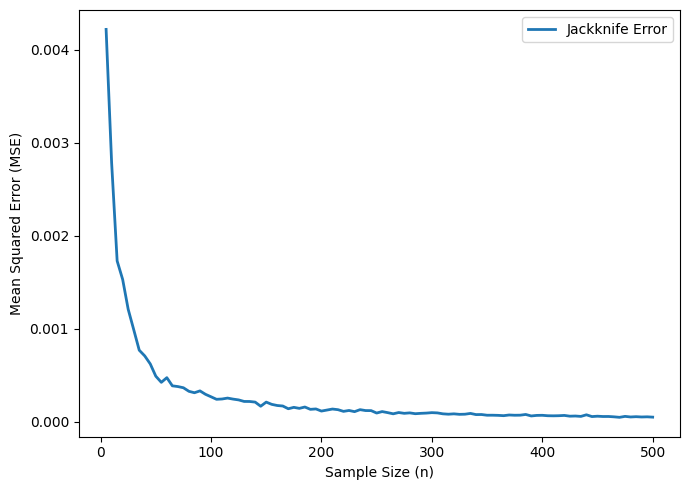

In [7]:
# Jackknife convergence
sample_sizes, jackknife_mse = plot_jackknife_convergence(
    dice_scores,
    max_sample_size=500,
    runs=300
)

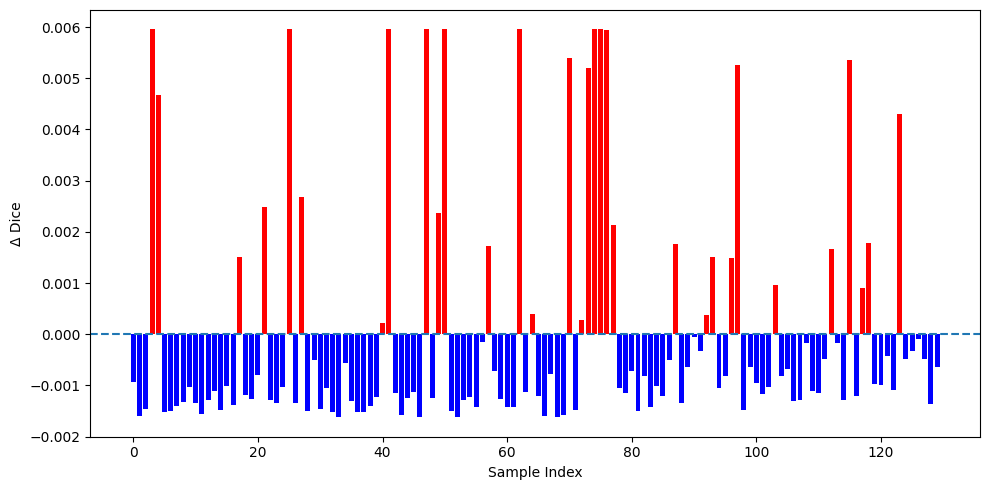

In [8]:
loo_results = plot_loo_sensitivity(dice_scores)

k=1 | Removed indices: [75] | New Mean Dice: 0.7741
k=2 | Removed indices: [75 74] | New Mean Dice: 0.7802
k=3 | Removed indices: [75 74 47] | New Mean Dice: 0.7863
k=4 | Removed indices: [75 74 47 41] | New Mean Dice: 0.7925
k=5 | Removed indices: [75 74 47 41 25] | New Mean Dice: 0.7989


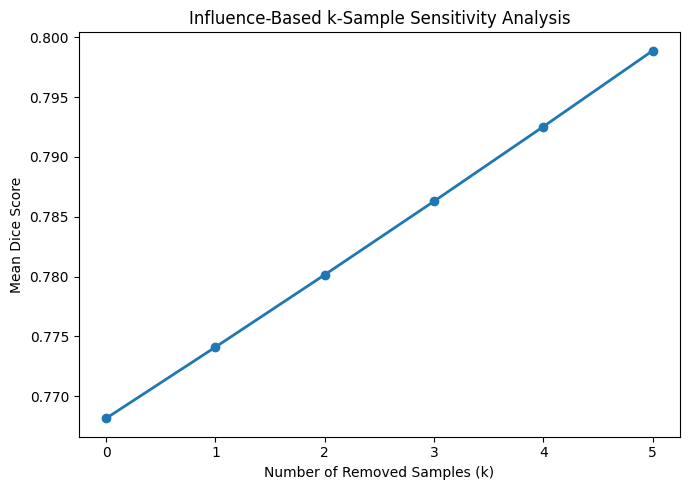

In [7]:
# K-sample sensitivity analysis
sensitivity_results = plot_k_sample_sensitivity(
    dice_scores,
    max_k=5
)